In [1]:
import os
from pathlib import Path
print(f'Changing to {Path().resolve().parent}')
os.chdir(Path().resolve().parent)

Changing to /home/bnoordijk/vscode_projects/halcyon


In [2]:
from halcyon.Models.CellBox import CellBox
from tests.create_dummy_data import create_ko_from_sample_data
from halcyon.Trainer import Trainer
from halcyon.Models.NeuralODE import NeuralODE

import logging

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [3]:
expressions = create_ko_from_sample_data()
expressions.scale_time_series()

In [4]:
expressions.all_environments

('test', 'test2')

In [4]:
# Cellbox run this
model = CellBox(expressions.genes)
model._set_epsilon_to_zero()
model._set_weight_matrix_to_random()

In [8]:
# Neural ODE run this
model = NeuralODE(expressions.genes, expressions.all_environments, additional_hidden_layers=5, hidden_size=64)

2025-04-30 11:38:35,441 - INFO - Epoch 0, loss 0.04384336993098259
2025-04-30 11:38:35,917 - INFO - Epoch 1, loss 0.044010695070028305
2025-04-30 11:38:36,342 - INFO - Epoch 2, loss 0.04385785758495331
2025-04-30 11:38:36,615 - INFO - Epoch 3, loss 0.04356410354375839
2025-04-30 11:38:36,896 - INFO - Epoch 4, loss 0.043338049203157425
2025-04-30 11:38:37,192 - INFO - Epoch 5, loss 0.043179113417863846
2025-04-30 11:38:37,474 - INFO - Epoch 6, loss 0.0429692380130291
2025-04-30 11:38:37,756 - INFO - Epoch 7, loss 0.042813219130039215
2025-04-30 11:38:38,091 - INFO - Epoch 8, loss 0.04265924543142319
2025-04-30 11:38:38,393 - INFO - Epoch 9, loss 0.042495932430028915
2025-04-30 11:38:38,690 - INFO - Epoch 10, loss 0.042284172028303146
2025-04-30 11:38:39,012 - INFO - Epoch 11, loss 0.04203657805919647
2025-04-30 11:38:39,340 - INFO - Epoch 12, loss 0.04180091246962547
2025-04-30 11:38:39,689 - INFO - Epoch 13, loss 0.041616033762693405
2025-04-30 11:38:40,011 - INFO - Epoch 14, loss 0.04

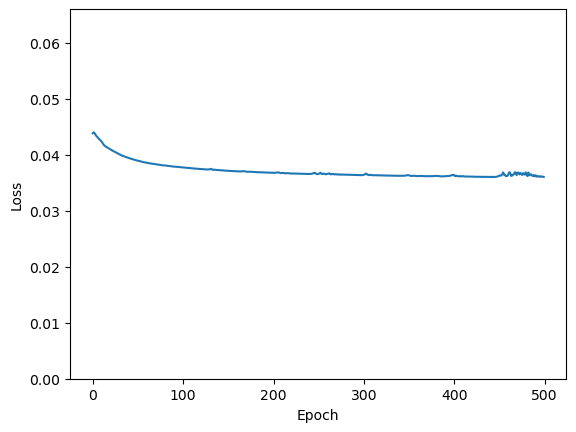

In [7]:
my_trainer = Trainer(model, expressions, batch_size=10, optimizer_kwargs={'lr': .1})
my_trainer.train(500)
my_trainer.plot_loss_history()

(<Figure size 1000x4000 with 20 Axes>,
 array([[<Axes: title={'center': 'Measured (Sample 0)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 0)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 1)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 1)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 2)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 2)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 3)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 3)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 4)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 4)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center'

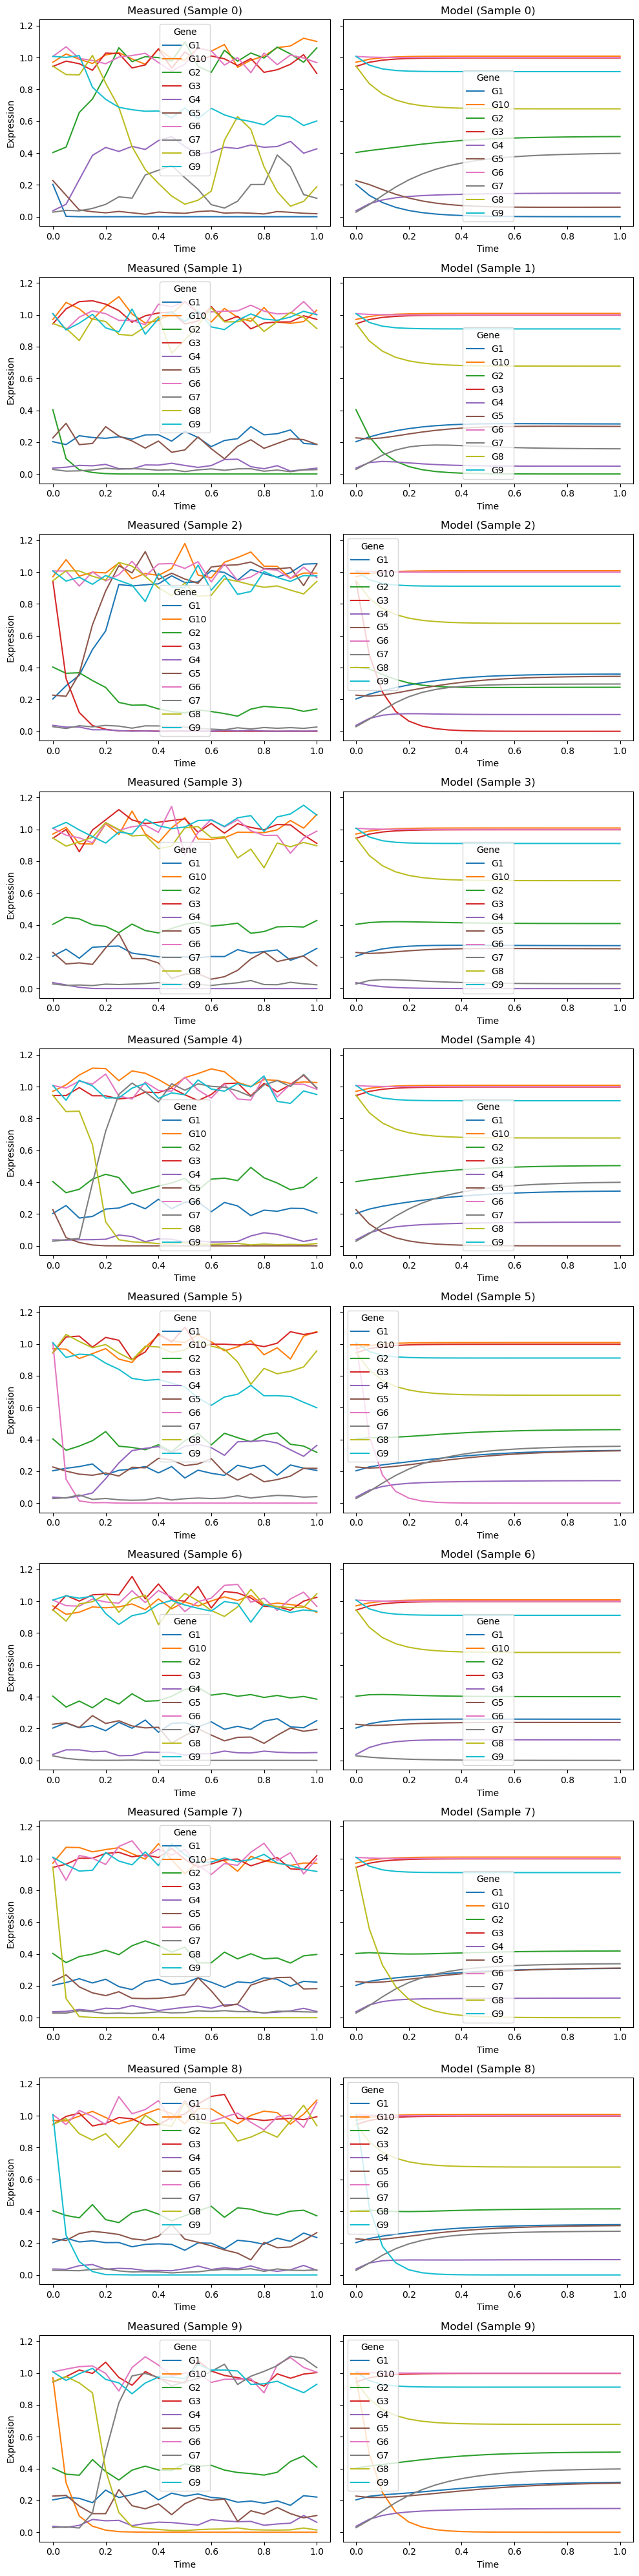

In [8]:
my_trainer.plot_fit_vs_real()